In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

In [4]:
df = pd.read_csv("../data/raw/weather.csv")
df.head()

,int_arc,temp_hi,dd_cool,bar,dew_in,date,et,timestamp,recept_iss,temp_in,...,dir_hi,speed_hi,heat_in,speed_wind,energy_solar,chill_wind,tx_wind,uv_hi,hum_in,_id
0,15,25.80,0.076,29.778,23.1,12-08-25,0.00,2025-08-12T02:00:00.000Z,100.0,28.70,...,W,1.6,32.60,0.0,2.95,25.7,1,0.0,72,008XmQwxvdWQFVn6FHBd
1,15,34.90,0.172,29.532,17.4,29-05-25,0.15,2025-05-29T11:30:00.000Z,100.0,24.90,...,ENE,11.3,25.50,4.8,2.30,34.9,1,0.5,63,00OHKOmSeoQGrEPBc31O
2,15,46.28,0.000,30.040,21.1,17-12-25,0.15,2025-12-17T14:01:51.000Z,100.0,46.00,...,Southeast,23.0,51.11,1.0,0.33,24.4,1,4.4,71,00Oq1V2VHGmeIGNFIlft
3,15,48.11,0.000,29.910,23.9,09-11-25,0.09,2025-11-09T07:46:39.000Z,100.0,46.89,...,East-southeast,16.0,53.89,9.0,6.77,30.6,1,3.4,67,00XUrQIrjkPlpfNgrHEn
4,15,45.89,0.000,30.050,20.0,03-02-26,0.14,2026-02-03T12:41:20.000Z,100.0,45.50,...,South-southeast,19.0,48.33,4.0,0.07,26.1,1,5.6,62,01j8Z7UgLaEchrvM0N1J


In [8]:
numeric_df = df.select_dtypes(include=['int64', 'float64'])
corr_matrix = numeric_df.corr()

print(corr_matrix)

                 int_arc   temp_hi   dd_cool       bar    dew_in        et  \
int_arc         1.000000  0.160505  0.042588 -0.036061 -0.093799  0.087358   
temp_hi         0.160505  1.000000 -0.698339  0.710291  0.064868  0.316720   
dd_cool         0.042588 -0.698339  1.000000 -0.827474 -0.256415 -0.062067   
bar            -0.036061  0.710291 -0.827474  1.000000  0.110826  0.138446   
dew_in         -0.093799  0.064868 -0.256415  0.110826  1.000000 -0.035824   
et              0.087358  0.316720 -0.062067  0.138446 -0.035824  1.000000   
recept_iss      0.082541  0.007627 -0.003274  0.002552  0.008089  0.005427   
temp_in         0.107965  0.892593 -0.876137  0.781667  0.314275  0.184849   
pt_dew         -0.040858 -0.538391  0.796527 -0.675335 -0.010857 -0.078590   
index_thsw      0.017444 -0.206538  0.790447 -0.540934 -0.195765  0.157929   
index_uv        0.069473  0.086415  0.306101 -0.082252 -0.027116  0.247958   
hum_out         0.017743 -0.030433 -0.564782  0.385690  0.262081

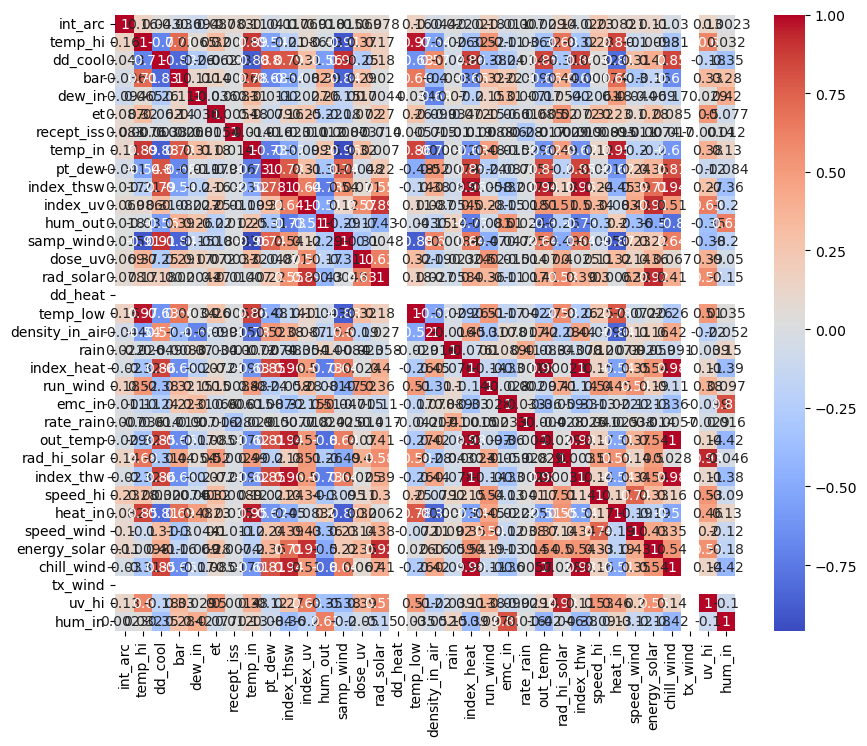

In [12]:
numeric_df.corr(method='pearson')
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')

plt.show()

In [15]:
threshold_low = 0.9
threshold_high = 0.95

for col in corr_matrix.columns:
    for row in corr_matrix.index:
        if col != row and abs(corr_matrix.loc[row, col]) > threshold_low and abs(corr_matrix.loc[row, col]) < threshold_high:
            print(row, col, corr_matrix.loc[row, col])

samp_wind temp_hi -0.908364621742648
samp_wind dd_cool 0.9147184105053845
out_temp index_thsw 0.9404449280326236
chill_wind index_thsw 0.9401262374939383
energy_solar index_uv 0.912902779040217
temp_hi samp_wind -0.908364621742648
dd_cool samp_wind 0.9147184105053845
energy_solar rad_solar 0.9244009074593637
index_thsw out_temp 0.9404449280326236
uv_hi rad_hi_solar 0.9313029870133982
index_uv energy_solar 0.912902779040217
rad_solar energy_solar 0.9244009074593637
index_thsw chill_wind 0.9401262374939383
rad_hi_solar uv_hi 0.9313029870133982


In [16]:
#samp_wind, heat_in, index_heat, index_thw, chill_wind, dd_cool, energy_solar, rad_solar, uv_hi, rad_hi_solar

In [23]:
drop_cols = [
    "samp_wind",
    "heat_in",
    "index_heat",
    "index_thw",
    "chill_wind",
    "dd_cool",
    "energy_solar",
    "rad_solar",
    "uv_hi",
    "rad_hi_solar"
]

numeric_df = numeric_df.drop(columns=drop_cols)

In [25]:
threshold_low = 0.9
threshold_high = 0.95
numeric_df.corr(method='pearson')
corr_matrix = numeric_df.corr()
for col in corr_matrix.columns:
    for row in corr_matrix.index:
        if col != row and abs(corr_matrix.loc[row, col]) > threshold_low and abs(corr_matrix.loc[row, col]) < threshold_high:
            print(row, col, corr_matrix.loc[row, col])

out_temp index_thsw 0.9404449280326236
index_thsw out_temp 0.9404449280326236


In [26]:
numeric_df.to_csv("../data/interim/cleaned_weather.csv")

In [28]:
numeric_df["timestamp"] = df["timestamp"]

In [29]:
numeric_df.head()

,int_arc,temp_hi,bar,dew_in,et,recept_iss,temp_in,pt_dew,index_thsw,index_uv,...,rain,run_wind,emc_in,rate_rain,out_temp,speed_hi,speed_wind,tx_wind,hum_in,timestamp
0,15,25.80,29.778,23.1,0.00,100.0,28.70,23.7,30.9,0.0,...,0.0,0.00,13.25,0.0,25.7,1.6,0.0,1,72,2025-08-12T02:00:00.000Z
1,15,34.90,29.532,17.4,0.15,100.0,24.90,25.4,45.7,0.1,...,0.0,1.21,11.41,0.0,34.9,11.3,4.8,1,63,2025-05-29T11:30:00.000Z
2,15,46.28,30.040,21.1,0.15,100.0,46.00,21.1,28.1,0.0,...,0.0,2.00,13.25,0.0,24.4,23.0,1.0,1,71,2025-12-17T14:01:51.000Z
3,15,48.11,29.910,23.9,0.09,100.0,46.89,23.9,37.6,2.6,...,0.0,5.00,13.25,0.0,30.3,16.0,9.0,1,67,2025-11-09T07:46:39.000Z
4,15,45.89,30.050,20.0,0.14,100.0,45.50,20.0,29.2,0.0,...,0.0,4.00,13.25,0.0,25.9,19.0,4.0,1,62,2026-02-03T12:41:20.000Z


In [30]:
numeric_df.to_csv("../data/interim/cleaned_weather.csv")

In [32]:
df.head(10)



,int_arc,temp_hi,bar,dew_in,date,et,timestamp,recept_iss,temp_in,pt_dew,...,rate_rain,time,out_temp,dir_wind,dir_hi,speed_hi,speed_wind,tx_wind,hum_in,_id
0,15,25.80,29.778,23.1,12-08-25,0.00,2025-08-12T02:00:00.000Z,100.0,28.70,23.7,...,0.0,7:30,25.7,W,W,1.6,0.0,1,72,008XmQwxvdWQFVn6FHBd
1,15,34.90,29.532,17.4,29-05-25,0.15,2025-05-29T11:30:00.000Z,100.0,24.90,25.4,...,0.0,17:00,34.9,NW,ENE,11.3,4.8,1,63,00OHKOmSeoQGrEPBc31O
2,15,46.28,30.040,21.1,17-12-25,0.15,2025-12-17T14:01:51.000Z,100.0,46.00,21.1,...,0.0,14:01,24.4,Southeast,Southeast,23.0,1.0,1,71,00Oq1V2VHGmeIGNFIlft
3,15,48.11,29.910,23.9,09-11-25,0.09,2025-11-09T07:46:39.000Z,100.0,46.89,23.9,...,0.0,7:46,30.3,East-southeast,East-southeast,16.0,9.0,1,67,00XUrQIrjkPlpfNgrHEn
4,15,45.89,30.050,20.0,03-02-26,0.14,2026-02-03T12:41:20.000Z,100.0,45.50,20.0,...,0.0,12:41,25.9,South-southeast,South-southeast,19.0,4.0,1,62,01j8Z7UgLaEchrvM0N1J
5,15,32.40,29.641,22.4,25-07-25,0.53,2025-07-25T07:30:00.000Z,100.0,29.40,26.2,...,0.0,13:00,32.4,NW,NW,17.7,8.0,1,66,01mONEZUANeP2zhxw3pa
6,15,33.10,29.667,21.3,30-09-25,0.00,2025-09-30T10:15:00.000Z,100.0,26.30,24.4,...,0.0,15:45,32.9,NE,ENE,30.6,20.9,1,74,01sP7hfH6XHyIlDk58bm
7,15,44.94,30.040,23.9,11-12-25,0.06,2025-12-11T05:46:54.000Z,100.0,44.67,23.9,...,0.0,5:46,27.2,Southeast,Southeast,16.0,3.0,1,78,023MGOG9UNaVpApQ29Tq
8,15,48.17,29.840,23.9,21-02-26,0.15,2026-02-21T11:41:14.000Z,100.0,46.67,23.9,...,0.0,11:41,28.9,South,South,17.0,5.0,1,70,023hCJ8bo1WWJtU6BQZO
9,15,27.30,29.699,22.1,26-07-25,0.05,2025-07-26T01:30:00.000Z,100.0,28.60,22.9,...,0.0,7:00,27.3,NW,NW,16.1,8.0,1,68,02VfMlRKEWk4sW1ODgjV


In [33]:
import pandas as pd

In [34]:
df = pd.read_csv("../data/interim/sub_s_cleanedtime.csv")

In [35]:
print(df.columns)


Index(['cleaned bucket', 'energy_kwh', 'Unnamed: 2', 'Unnamed: 3',
       'Unnamed: 4', 'Unnamed: 5'],
      dtype='object')


In [36]:
df["cleaned bucket"] = pd.to_datetime(df["cleaned bucket"])

In [37]:
df_hourly = (
    df.groupby("cleaned bucket", as_index=False)["energy_kwh"]
    .sum()
)

In [38]:
df_hourly = df_hourly.sort_values("cleaned bucket")

In [39]:
df.head


<bound method NDFrame.head of            cleaned bucket  energy_kwh  Unnamed: 2  Unnamed: 3  Unnamed: 4  \
0     2025-09-20 05:00:00  2810961.00         NaN         NaN         NaN   
1     2025-09-20 05:00:00  2810987.00         NaN         NaN         NaN   
2     2025-09-20 05:00:00  2811015.50         NaN         NaN         NaN   
3     2025-09-20 05:00:00  2811029.75         NaN         NaN         NaN   
4     2025-09-20 05:00:00  2811034.25         NaN         NaN         NaN   
...                   ...         ...         ...         ...         ...   
39732 2026-02-26 10:00:00  3377349.75         NaN         NaN         NaN   
39733 2026-02-26 12:00:00  3377521.25         NaN         NaN         NaN   
39734 2026-02-26 12:00:00  3377563.00         NaN         NaN         NaN   
39735 2026-02-26 12:00:00  3377603.75         NaN         NaN         NaN   
39736 2026-02-26 12:00:00  3377644.25         NaN         NaN         NaN   

       Unnamed: 5  
0             NaN  
1    

: 